# Tugas: Clustering dengan DBSCAN, BIRCH, dan EM (Gaussian Mixture Model)

| Nama | NRP |
|------|-----|
| Fahmi Alfayadh | 5054251015 |

## Deskripsi Tugas

Pada tugas ini, kalian akan melakukan clustering pada data pelanggan pusat perbelanjaan (*Mall Customer Segmentation*). Kalian akan membandingkan tiga pendekatan clustering:

1. **DBSCAN**, yang membentuk cluster berdasarkan kepadatan data dan dapat menandai data sebagai noise.
2. **BIRCH**, yang merangkum data ke dalam struktur pohon untuk membentuk subcluster.
3. **Expectation-Maximization (EM)** menggunakan **Gaussian Mixture Model (GMM)**, yang memodelkan data sebagai campuran beberapa distribusi probabilitas.

Dataset: [Mall Customer Segmentation Data di Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data).

Setiap baris mewakili satu pelanggan. Pada tugas ini, gunakan dua fitur agar hasilnya mudah divisualisasikan:
- `Annual Income (k$)`: pendapatan tahunan dalam ribuan dolar.
- `Spending Score (1-100)`: skor pengeluaran pelanggan.

**Penting:** `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Kolom `Gender` juga tidak digunakan dalam eksperimen utama agar fokus tetap pada dua fitur numerik. Kolom tersebut boleh digunakan untuk interpretasi tambahan setelah model selesai, bukan sebagai input model.

## Tujuan Pembelajaran

- Melakukan eksplorasi dan preprocessing data sederhana.
- Memahami mengapa feature scaling diperlukan.
- Menjalankan DBSCAN, BIRCH, dan GMM dengan EM.
- Memahami parameter utama dan karakteristik setiap algoritma.
- Membandingkan hasil clustering menggunakan visualisasi dan metrik evaluasi internal.

## Persiapan Dataset

Unduh file CSV dari halaman Kaggle di atas. Letakkan file `Mall_Customers.csv` di folder yang sama dengan notebook ini. Nama file biasanya `Mall_Customers.csv`.

Langkah pengerjaan:
1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM menggunakan Gaussian Mixture Model.
6. Evaluasi dan perbandingan model.
7. Analisis serta kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan:
# pandas, numpy, matplotlib, seaborn
# StandardScaler dari sklearn.preprocessing
# DBSCAN dari sklearn.cluster
# Birch dari sklearn.cluster
# GaussianMixture dari sklearn.mixture
# silhouette_score, davies_bouldin_score, calinski_harabasz_score dari sklearn.metrics
import polars as pl
import polars.selectors as ps
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import scipy.stats as stats


In [2]:
# Muat Mall_Customers.csv ke dalam DataFrame bernama df.
# Jika file tidak ditemukan, periksa lokasi file dan nama file.
# Tampilkan 5 baris pertama, jumlah baris/kolom, tipe data, statistik deskriptif,
# jumlah missing value, dan jumlah baris duplikat.

df = pl.read_csv('Mall_Customers.csv')
df.head(5)


CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
i64,str,i64,i64,i64
1,"""Male""",19,15,39
2,"""Male""",21,15,81
3,"""Female""",20,16,6
4,"""Female""",23,16,77
5,"""Female""",31,17,40


In [3]:
print(f"Jumlah baris: {df.shape[0]}, Jumlah kolom: {df.shape[1]}")
print(f"Tipe data:\n{df.dtypes}")
print(f"Statistik deskriptif:\n{df.describe()}")
print(f"Jumlah missing value:\n{df.null_count()}")
print(f"Jumlah baris duplikat: {df.is_duplicated().sum()}")

Jumlah baris: 200, Jumlah kolom: 5
Tipe data:
[Int64, String, Int64, Int64, Int64]
Statistik deskriptif:
shape: (9, 6)
┌────────────┬────────────┬────────┬───────────┬────────────────────┬────────────────────────┐
│ statistic  ┆ CustomerID ┆ Gender ┆ Age       ┆ Annual Income (k$) ┆ Spending Score (1-100) │
│ ---        ┆ ---        ┆ ---    ┆ ---       ┆ ---                ┆ ---                    │
│ str        ┆ f64        ┆ str    ┆ f64       ┆ f64                ┆ f64                    │
╞════════════╪════════════╪════════╪═══════════╪════════════════════╪════════════════════════╡
│ count      ┆ 200.0      ┆ 200    ┆ 200.0     ┆ 200.0              ┆ 200.0                  │
│ null_count ┆ 0.0        ┆ 0      ┆ 0.0       ┆ 0.0                ┆ 0.0                    │
│ mean       ┆ 100.5      ┆ null   ┆ 38.85     ┆ 60.56              ┆ 50.2                   │
│ std        ┆ 57.879185  ┆ null   ┆ 13.969007 ┆ 26.264721          ┆ 25.823522              │
│ min        ┆ 1.0        

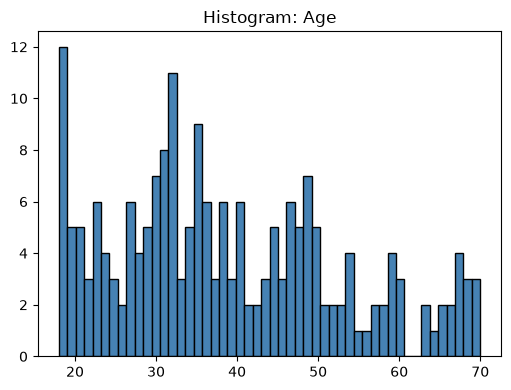

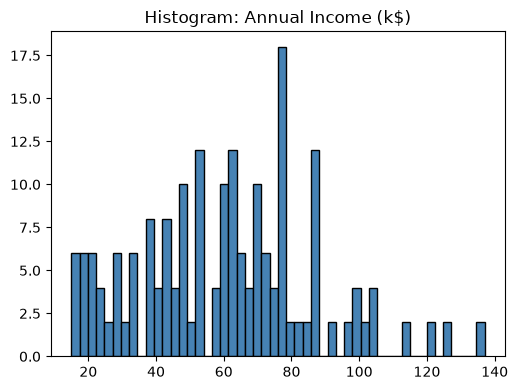

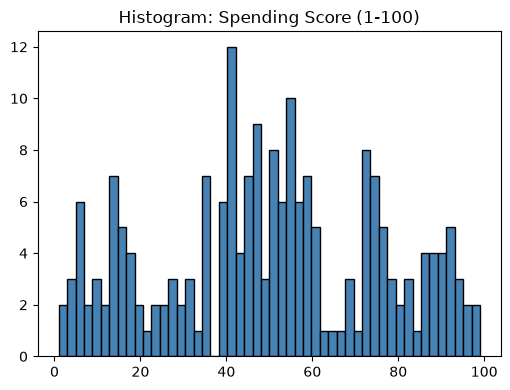

In [4]:
# Tampilkan distribusi Annual Income (k$) dan Spending Score (1-100)
# menggunakan histogram dan/atau boxplot.
# Amati rentang, bentuk distribusi, dan kemungkinan outlier.
df = df.drop("CustomerID")
numeric_cols = df.select(ps.numeric()).columns

for kolom in numeric_cols:
    arr = df[kolom].to_numpy()

    plt.figure(figsize=(10, 4))

    # Histogram
    plt.subplot(1, 2, 1)
    plt.hist(arr, bins=50, edgecolor="black", color="steelblue")
    plt.title(f"Histogram: {kolom}")

    plt.tight_layout()
    plt.show()

/tmp/ipykernel_52271/3645897043.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(arr, vert=False)


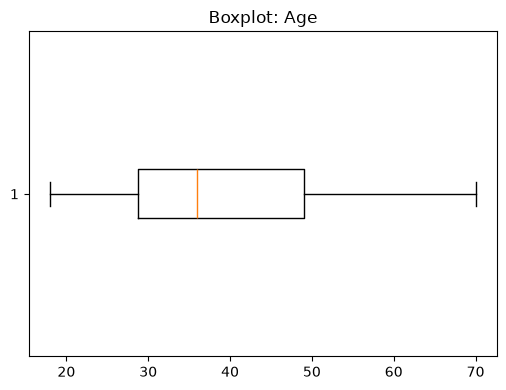

/tmp/ipykernel_52271/3645897043.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(arr, vert=False)


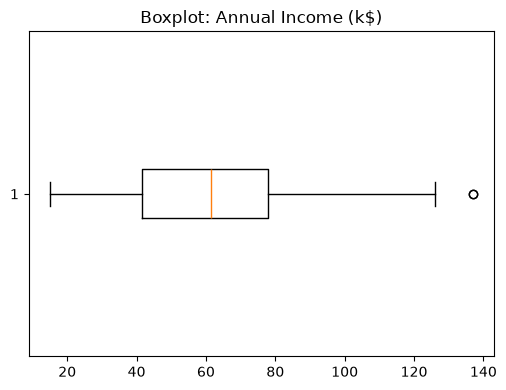

/tmp/ipykernel_52271/3645897043.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(arr, vert=False)


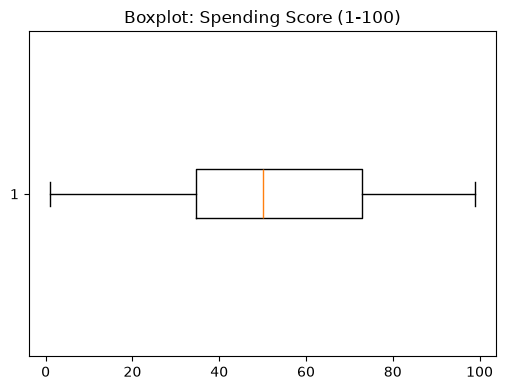

In [5]:
for kolom in numeric_cols:
    arr = df[kolom].to_numpy()

    plt.figure(figsize=(10, 4))

    # Boxplot
    plt.subplot(1, 2, 1)
    plt.boxplot(arr, vert=False)
    plt.title(f"Boxplot: {kolom}")

    plt.tight_layout()
    plt.show()

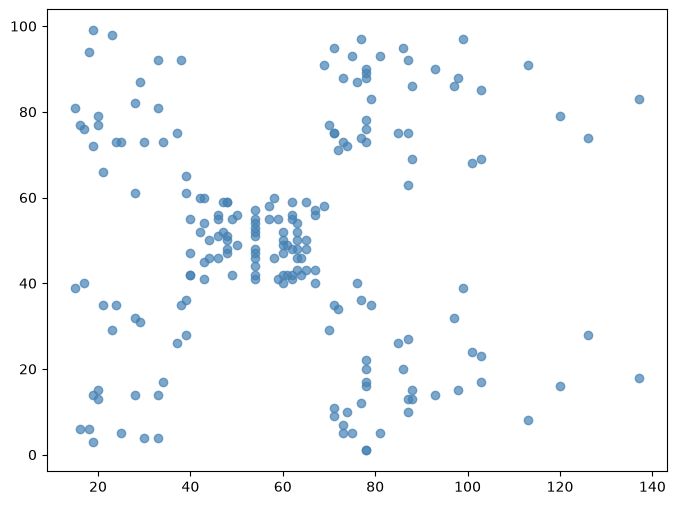

In [6]:
# Buat scatter plot dari Annual Income (k$) terhadap Spending Score (1-100).
# Jangan warnai berdasarkan label apa pun terlebih dahulu.
# Amati apakah terlihat kelompok-kelompok yang terpisah.

plt.figure(figsize=(8, 6))
plt.scatter(df["Annual Income (k$)"].to_numpy(), df["Spending Score (1-100)"].to_numpy(), alpha=0.7, color="steelblue")

## Pertanyaan EDA

Tuliskan pengamatan singkat:
- Apakah ada missing value atau baris duplikat? 

answer: Tidak ada missing value dan tidak ada baris duplikat pada dataset ini.

- Bagaimana rentang pendapatan dan spending score?

answer: Rentang pendapatan tahunan (Annual Income) adalah dari 15 k$ hingga 137 k$, sedangkan rentang spending score adalah dari 1 hingga 99.

- Apakah kedua fitur tampak memiliki kelompok yang terpisah?

answer: Ya, kedua fitur tampak memiliki kelompok yang terpisah, terlihat dari scatter plot yang menunjukkan beberapa cluster yang berbeda pada visualisasi sebelumnya.

# 2. Preprocessing

In [7]:
# Periksa dan tangani missing value serta baris duplikat jika ditemukan.
# Karena CustomerID adalah identitas, jangan masukkan kolom tersebut ke fitur clustering.
# Pilih dua fitur numerik:
#   Annual Income (k$)
#   Spending Score (1-100)
# Simpan dalam DataFrame X.

X = df.select(["Annual Income (k$)", "Spending Score (1-100)"])

In [8]:
# Lakukan feature scaling menggunakan StandardScaler.
# Simpan hasilnya sebagai X_scaled.
# Ubah hasil scaling menjadi DataFrame agar nama kolom tetap terlihat.
# Tampilkan beberapa baris X_scaled dan statistik deskriptifnya.

scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(X.to_numpy())
X_scaled = pl.DataFrame(X_scaled_array, schema=X.columns)

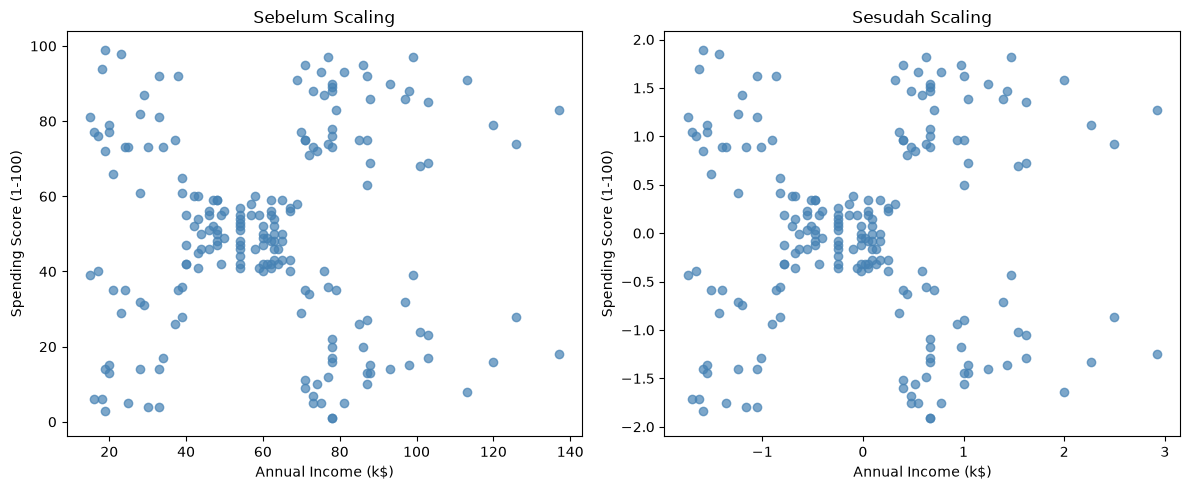

In [9]:
# Buat scatter plot sebelum dan sesudah scaling.
# Jelaskan mengapa scaling penting, terutama ketika algoritma menggunakan jarak
# atau mengasumsikan skala fitur yang sebanding.

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
# Scatter plot sebelum scaling
axes[0].scatter(X["Annual Income (k$)"].to_numpy(), X["Spending Score (1-100)"].to_numpy(), alpha=0.7, color="steelblue")
axes[0].set_title("Sebelum Scaling")
axes[0].set_xlabel("Annual Income (k$)")
axes[0].set_ylabel("Spending Score (1-100)")    

# Scatter plot sesudah scaling
axes[1].scatter(X_scaled["Annual Income (k$)"].to_numpy(), X_scaled["Spending Score (1-100)"].to_numpy(), alpha=0.7, color="steelblue")
axes[1].set_title("Sesudah Scaling")
axes[1].set_xlabel("Annual Income (k$)")
axes[1].set_ylabel("Spending Score (1-100)")

plt.tight_layout()

Perbedaan di skala terlihat pada skala nya saja, secara "bentuk" masih sama antara sblm vs sesudah. 

Scaler penting karena algoritma clustering seperti DBSCAN, BIRCH, dan GMM sensitif terhadap skala fitur. Jika fitur memiliki skala yang berbeda, fitur dengan skala lebih besar dapat mendominasi perhitungan jarak, sehingga mempengaruhi hasil clustering. Dengan melakukan feature scaling, kita memastikan bahwa semua fitur berkontribusi secara seimbang dalam proses clustering.

**Fitur yang digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)`.

Tuliskan alasan pemilihan kedua fitur tersebut dan jelaskan mengapa `CustomerID` tidak digunakan.

Answer: Kedua fitur ini dipilih karena mereka memberikan informasi yang relevan tentang perilaku pelanggan dalam hal pendapatan dan pengeluaran. `CustomerID` tidak digunakan karena hanya berfungsi sebagai identitas unik untuk setiap pelanggan dan tidak memberikan informasi yang berguna untuk proses clustering.

# 3. Eksperimen DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) membentuk cluster dari kumpulan titik yang padat. Titik yang tidak memenuhi kepadatan minimum dapat diberi label `-1`, yang berarti noise.

Parameter utama:
- `eps`: jarak maksimum agar dua titik dianggap berdekatan.
- `min_samples`: jumlah minimum titik di sekitar suatu titik agar titik tersebut dianggap sebagai titik inti (*core point*).

DBSCAN tidak perlu menentukan jumlah cluster di awal, tetapi hasilnya sensitif terhadap `eps` dan `min_samples`.

In [10]:
# Jalankan DBSCAN pada X_scaled.
# Mulai dengan eps dan min_samples yang masuk akal, misalnya eps=0.3 dan min_samples=5.
# Simpan label hasil clustering sebagai labels_dbscan.
# Catatan: nilai eps perlu dicoba dan dievaluasi, bukan dianggap pasti paling baik.

dbscan = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_scaled.to_numpy())

Jumlah cluster (tanpa noise): 7
Jumlah titik noise: 35
Label -1: 35 anggota
Label 0: 12 anggota
Label 1: 5 anggota
Label 2: 7 anggota
Label 3: 88 anggota
Label 4: 30 anggota
Label 5: 14 anggota
Label 6: 9 anggota


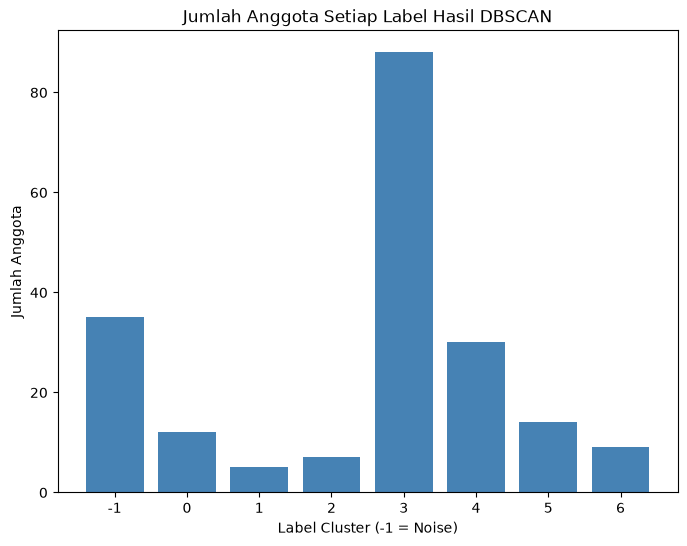

In [11]:
# Tampilkan jumlah anggota setiap label hasil DBSCAN.
# Hitung jumlah cluster dengan tidak memasukkan label -1.
# Hitung juga jumlah titik noise (label -1).

unique_labels, counts = np.unique(labels_dbscan, return_counts=True)
label_counts = dict(zip(unique_labels, counts))
num_clusters = len(unique_labels) - (1 if -1 in unique_labels else 0)
num_noise = label_counts.get(-1, 0)

print(f"Jumlah cluster (tanpa noise): {num_clusters}")
print(f"Jumlah titik noise: {num_noise}")
for label, count in label_counts.items():
    print(f"Label {label}: {count} anggota")

plt.figure(figsize=(8, 6))
plt.bar([str(k) for k in label_counts.keys()], list(label_counts.values()), color="steelblue")
plt.title("Jumlah Anggota Setiap Label Hasil DBSCAN")
plt.xlabel("Label Cluster (-1 = Noise)")
plt.ylabel("Jumlah Anggota")
plt.show()


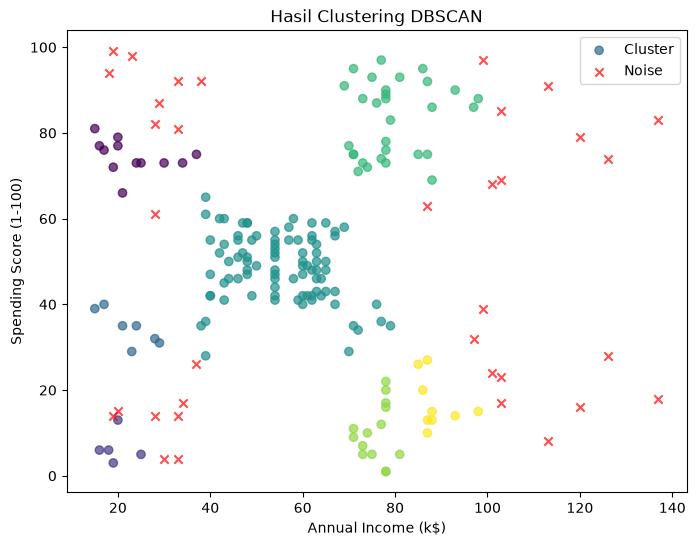

In [12]:
# Buat scatter plot hasil DBSCAN berdasarkan labels_dbscan.
# Gunakan X_scaled atau X untuk koordinat plot; untuk interpretasi, X (fitur asli)
# biasanya lebih mudah dipahami.
# Beri judul dan label sumbu yang jelas, serta pastikan noise dapat dibedakan.

plt.figure(figsize=(8, 6))
noise_mask = labels_dbscan == -1
plt.scatter(
    X["Annual Income (k$)"].to_numpy()[~noise_mask],
    X["Spending Score (1-100)"].to_numpy()[~noise_mask],
    c=labels_dbscan[~noise_mask],
    cmap='viridis',
    alpha=0.7,
    label='Cluster'
)
plt.scatter(
    X["Annual Income (k$)"].to_numpy()[noise_mask],
    X["Spending Score (1-100)"].to_numpy()[noise_mask],
    color='red',
    marker='x',
    alpha=0.7,
    label='Noise'
)
plt.title("Hasil Clustering DBSCAN")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.show()


In [13]:
# Coba beberapa kombinasi eps dan min_samples.
# Buat tabel ringkasan yang berisi eps, min_samples, jumlah cluster (tanpa noise),
# jumlah noise, dan Silhouette Score jika metrik tersebut valid.
# Hindari menghitung silhouette jika hasilnya hanya satu cluster atau semua titik noise.

eps_list = [0.2, 0.3, 0.4]
min_samples_list = [3, 5, 7]
dbscan_results = []

for eps in eps_list:
    for min_samples in min_samples_list:
        dbscan = DBSCAN(eps=eps, min_samples=min_samples)
        labels = dbscan.fit_predict(X_scaled.to_numpy())
        
        unique_labels, counts = np.unique(labels, return_counts=True)
        num_clusters = len(unique_labels) - (1 if -1 in unique_labels else 0)
        num_noise = counts[unique_labels == -1][0] if -1 in unique_labels else 0
        
        silhouette = silhouette_score(X_scaled.to_numpy(), labels) if num_clusters > 1 else None
        
        dbscan_results.append({
            "eps": eps,
            "min_samples": min_samples,
            "clusters": num_clusters,
            "noise": num_noise,
            "silhouette": silhouette
        })

df_dbscan_summary = pl.DataFrame(dbscan_results)
df_dbscan_summary


eps,min_samples,clusters,noise,silhouette
f64,i64,i64,i64,f64
0.2,3,13,44,0.230585
0.2,5,7,77,0.140579
0.2,7,4,100,0.055593
0.3,3,9,14,0.413619
0.3,5,7,35,0.316141
0.3,7,4,72,0.231465
0.4,3,4,10,0.362691
0.4,5,4,15,0.413258
0.4,7,4,20,0.404304


### Analisis DBSCAN

- Apa pengaruh kenaikan `eps` terhadap jumlah cluster dan noise?

answer: Kenaikan `eps` memperbesar radius jangkauan ketetanggaan titik inti (*core point*). Akibatnya, titik-titik lebih mudah saling terhubung menjadi cluster, jumlah titik noise berkurang drastis, dan jumlah cluster cenderung menurun karena cluster-cluster yang berdekatan melebur (misal pada `min_samples=5`, menaikkan `eps` dari 0.2 ke 0.4 mengurangi noise dari 77 menjadi 15 titik serta mengurangi cluster dari 7 menjadi 4).

- Apa pengaruh `min_samples`?

answer: Kenaikan `min_samples` meningkatkan batas jumlah titik tetangga minimum agar suatu titik dinyatakan sebagai titik inti. Akibatnya, ambang kepadatan meningkat, jumlah titik noise bertambah, dan jumlah cluster yang terbentuk berkurang karena area berdensitas rendah tidak lagi memenuhi syarat sebagai cluster (misal pada `eps=0.3`, menaikkan `min_samples` dari 3 ke 7 menaikkan noise dari 14 ke 72 titik serta menurunkan cluster dari 9 menjadi 4).

- Apakah ada kombinasi parameter yang menghasilkan satu cluster besar atau terlalu banyak noise?

answer:
- Terlalu banyak noise: Kombinasi `eps=0.2, min_samples=7` menghasilkan 100 titik noise (50% dari total 200 data).
- Terlalu sedikit cluster / melebur: Pada `eps=0.5` (dengan `min_samples` 3, 5, maupun 7), model hanya menghasilkan 2 cluster besar karena sebagian besar data di area tengah langsung melebur menjadi satu kepadatan.


# 4. Eksperimen BIRCH

BIRCH (*Balanced Iterative Reducing and Clustering using Hierarchies*) membangun struktur pohon ringkasan cluster. Parameter `threshold` mengatur seberapa dekat titik harus berada agar dapat digabungkan dalam subcluster. `n_clusters` menentukan jumlah cluster akhir jika diberikan.

Berbeda dari DBSCAN, BIRCH tidak memberi label noise secara eksplisit.

In [14]:
# Latih model Birch pada X_scaled.
# Coba threshold awal, misalnya 0.5, dan n_clusters=5.
# Simpan label hasil clustering sebagai labels_birch.
# Catatan: jumlah cluster akhir dapat berubah sesuai parameter yang digunakan.

birch = Birch(threshold=0.5, n_clusters=5)
labels_birch = birch.fit_predict(X_scaled.to_numpy())


In [15]:
# Tampilkan jumlah anggota setiap cluster BIRCH.
# Tampilkan juga jumlah cluster yang terbentuk.

unique_birch, counts_birch = np.unique(labels_birch, return_counts=True)
num_clusters_birch = len(unique_birch)

print(f"Jumlah cluster BIRCH: {num_clusters_birch}")
for label, count in zip(unique_birch, counts_birch):
    print(f"Cluster {label}: {count} anggota")


Jumlah cluster BIRCH: 5
Cluster 0: 36 anggota
Cluster 1: 109 anggota
Cluster 2: 8 anggota
Cluster 3: 25 anggota
Cluster 4: 22 anggota


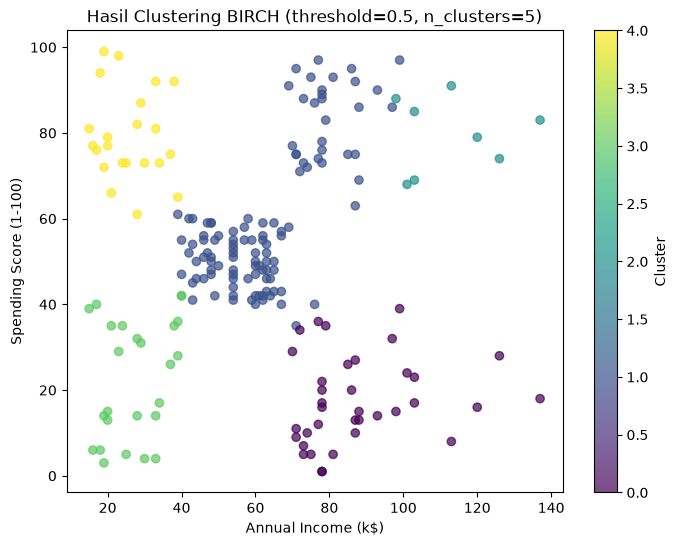

In [16]:
# Buat scatter plot hasil BIRCH pada ruang fitur asli X.
# Warnai titik berdasarkan labels_birch.

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X["Annual Income (k$)"].to_numpy(),
    X["Spending Score (1-100)"].to_numpy(),
    c=labels_birch,
    cmap="viridis",
    alpha=0.7
)
plt.title("Hasil Clustering BIRCH (threshold=0.5, n_clusters=5)")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.colorbar(scatter, label="Cluster")
plt.show()


In [17]:
# Bandingkan beberapa nilai threshold (misalnya 0.3, 0.5, 0.7, 1.0)
# dengan jumlah cluster akhir yang sama jika memungkinkan.
# Buat tabel berisi threshold, jumlah cluster, dan Silhouette Score bila valid.

threshold_list = [0.3, 0.5, 0.7, 1.0]
results_birch = []

for t in threshold_list:
    model_birch = Birch(threshold=t, n_clusters=5)
    labels = model_birch.fit_predict(X_scaled.to_numpy())
    n_clusters = len(np.unique(labels))
    sil = silhouette_score(X_scaled.to_numpy(), labels) if n_clusters > 1 else None
    
    results_birch.append({
        "threshold": t,
        "n_clusters": n_clusters,
        "silhouette": sil
    })

df_birch_summary = pl.DataFrame(results_birch)
df_birch_summary


/home/data/kuliah/rka/ML/Asset/Modul-Praktikum-ML-RKA/7. DBSCAN, BIRCH, EM/.venv/lib/python3.11/site-packages/sklearn/cluster/_birch.py:711: ConvergenceWarning: Number of subclusters found (4) by BIRCH is less than (5). Decrease the threshold.
  warnings.warn(


threshold,n_clusters,silhouette
f64,i64,f64
0.3,5,0.478062
0.5,5,0.41445
0.7,5,0.420676
1.0,4,0.388557


### Analisis BIRCH

- Apa yang terjadi pada jumlah cluster ketika `threshold` diperbesar?

answer: Kenaikan `threshold` memperbesar radius toleransi sub-cluster pada leaf node pohon CF, sehingga lebih banyak titik tergabung dalam sub-cluster yang sama. Jika tanpa pembatasan cluster (`n_clusters=None`), jumlah sub-cluster menurun (dari 23 pada threshold 0.3 menjadi 4 pada threshold 1.0). Jika `n_clusters=5` ditentukan, jumlah cluster akhir dapat dipertahankan sebanyak 5 selama jumlah sub-cluster dasar $\ge 5$; namun pada `threshold=1.0`, sub-cluster awal pada pohon CF hanya berjumlah 4 sehingga cluster akhir terpaksa menjadi 4.

- Apa perbedaan BIRCH dan DBSCAN dalam menangani titik yang berada jauh dari kelompok utama?

answer: DBSCAN mengidentifikasi titik terisolasi pada area berdensitas rendah sebagai noise (label `-1`). Sebaliknya, BIRCH tidak memiliki mekanisme pelabelan noise secara eksplisit; semua titik data dipaksa bergabung ke dalam sub-cluster atau cluster terdekat.

- Apakah hasil BIRCH berubah ketika `n_clusters` ditentukan?

answer: Ya. Saat `n_clusters` ditentukan (misal 5), BIRCH menerapkan fase global clustering lanjutan (menggunakan Agglomerative Clustering) pada sub-cluster CF-Tree untuk mengelompokkannya hingga tepat berjumlah `n_clusters`. Jika `n_clusters=None`, hasil clustering murni berupa sub-cluster langsung dari daun CF-Tree.


# 5. Eksperimen EM dengan Gaussian Mixture Model

Expectation-Maximization (EM) adalah algoritma iteratif untuk mengestimasi parameter model probabilistik. Dalam praktikum ini, EM digunakan untuk melatih **Gaussian Mixture Model (GMM)**.

GMM menganggap data berasal dari campuran beberapa distribusi Gaussian. Untuk setiap titik, GMM menghasilkan probabilitas keanggotaan pada setiap komponen, kemudian label cluster ditentukan dari komponen dengan probabilitas terbesar.

Parameter utama:
- `n_components`: jumlah distribusi Gaussian/cluster yang dimodelkan.
- `covariance_type`: bentuk matriks kovarians yang digunakan.
- `random_state`: agar hasil eksperimen dapat diulang.

In [18]:
# Latih GaussianMixture pada X_scaled menggunakan EM.
# Mulai dengan n_components=5, covariance_type='full', dan random_state=42.
# Simpan label hasil prediksi sebagai labels_gmm.

gmm = GaussianMixture(n_components=5, covariance_type="full", random_state=42)
labels_gmm = gmm.fit_predict(X_scaled.to_numpy())


In [19]:
# Tampilkan jumlah anggota setiap cluster GMM.
# Gunakan predict_proba untuk melihat probabilitas keanggotaan tiap titik.
# Tampilkan beberapa baris probabilitas dan periksa apakah ada titik dengan
# keanggotaan yang relatif tidak pasti.

unique_gmm, counts_gmm = np.unique(labels_gmm, return_counts=True)
print("Jumlah anggota setiap cluster GMM:")
for label, count in zip(unique_gmm, counts_gmm):
    print(f"Cluster {label}: {count} anggota")

probs_gmm = gmm.predict_proba(X_scaled.to_numpy())
print("\n5 baris pertama probabilitas keanggotaan:")
print(np.round(probs_gmm[:5], 4))

# Periksa titik dengan probabilitas maksimum < 0.8 (keanggotaan tidak pasti / perbatasan)
max_probs = probs_gmm.max(axis=1)
uncertain_indices = np.where(max_probs < 0.8)[0]
print(f"\nJumlah titik dengan probabilitas maksimum < 0.8: {len(uncertain_indices)}")
for idx in uncertain_indices[:5]:
    print(f"Indeks {idx}: max prob = {max_probs[idx]:.4f}, probabilitas = {np.round(probs_gmm[idx], 4)}")


Jumlah anggota setiap cluster GMM:
Cluster 0: 84 anggota
Cluster 1: 39 anggota
Cluster 2: 21 anggota
Cluster 3: 33 anggota
Cluster 4: 23 anggota

5 baris pertama probabilitas keanggotaan:
[[0.000e+00 0.000e+00 1.000e-03 0.000e+00 9.990e-01]
 [0.000e+00 2.000e-04 9.998e-01 0.000e+00 0.000e+00]
 [0.000e+00 0.000e+00 0.000e+00 2.000e-04 9.998e-01]
 [1.000e-04 2.000e-04 9.997e-01 0.000e+00 0.000e+00]
 [1.000e-04 0.000e+00 1.600e-03 0.000e+00 9.984e-01]]

Jumlah titik dengan probabilitas maksimum < 0.8: 6
Indeks 27: max prob = 0.6746, probabilitas = [2.785e-01 5.000e-04 6.746e-01 0.000e+00 4.640e-02]
Indeks 48: max prob = 0.6114, probabilitas = [6.114e-01 0.000e+00 3.000e-04 0.000e+00 3.883e-01]
Indeks 49: max prob = 0.6114, probabilitas = [6.114e-01 0.000e+00 3.000e-04 0.000e+00 3.883e-01]
Indeks 55: max prob = 0.7959, probabilitas = [7.959e-01 0.000e+00 1.000e-04 0.000e+00 2.040e-01]
Indeks 124: max prob = 0.5029, probabilitas = [0.4971 0.     0.     0.5029 0.    ]


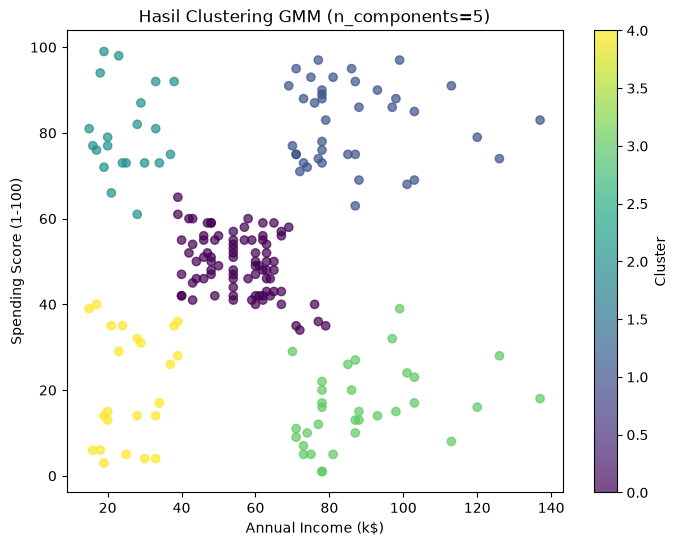

In [20]:
# Buat scatter plot hasil GMM pada ruang fitur asli X.
# Warnai titik berdasarkan labels_gmm.

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X["Annual Income (k$)"].to_numpy(),
    X["Spending Score (1-100)"].to_numpy(),
    c=labels_gmm,
    cmap="viridis",
    alpha=0.7
)
plt.title("Hasil Clustering GMM (n_components=5)")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.colorbar(scatter, label="Cluster")
plt.show()


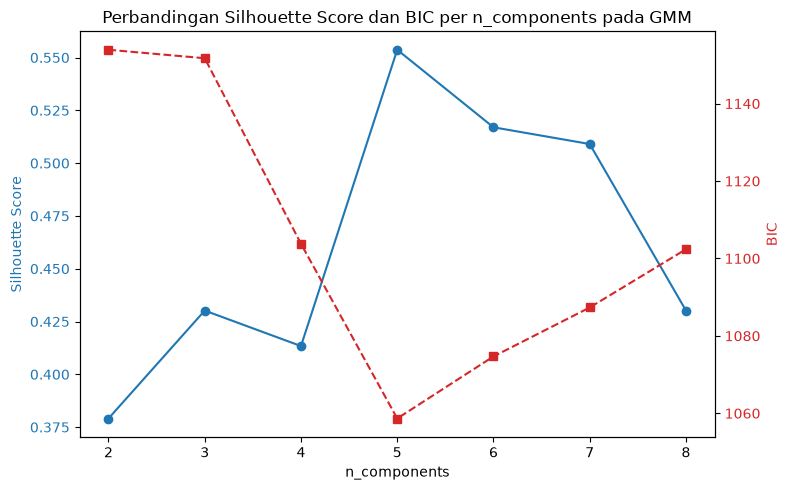

n_components,silhouette,bic
i64,f64,f64
2,0.379082,1153.904655
3,0.43019,1151.718274
4,0.413392,1103.790149
5,0.553689,1058.652252
6,0.516982,1074.682807
7,0.509057,1087.328517
8,0.43021,1102.370701


In [21]:
# Bandingkan beberapa nilai n_components (misalnya 2 sampai 8).
# Catat Silhouette Score dan BIC untuk setiap model.
# BIC yang lebih rendah menunjukkan keseimbangan model dan kecocokan data yang lebih baik
# menurut kriteria BIC, tetapi tetap perlu dipertimbangkan bersama visualisasi dan konteks.

gmm_results = []

for n in range(2, 9):
    model_gmm = GaussianMixture(n_components=n, covariance_type="full", random_state=42)
    labels = model_gmm.fit_predict(X_scaled.to_numpy())
    sil = silhouette_score(X_scaled.to_numpy(), labels)
    bic = model_gmm.bic(X_scaled.to_numpy())
    
    gmm_results.append({
        "n_components": n,
        "silhouette": sil,
        "bic": bic
    })

df_gmm_summary = pl.DataFrame(gmm_results)

fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(df_gmm_summary["n_components"].to_numpy(), df_gmm_summary["silhouette"].to_numpy(), marker="o", color="tab:blue")
ax1.set_xlabel("n_components")
ax1.set_ylabel("Silhouette Score", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")

ax2 = ax1.twinx()
ax2.plot(df_gmm_summary["n_components"].to_numpy(), df_gmm_summary["bic"].to_numpy(), marker="s", color="tab:red", linestyle="--")
ax2.set_ylabel("BIC", color="tab:red")
ax2.tick_params(axis="y", labelcolor="tab:red")

plt.title("Perbandingan Silhouette Score dan BIC per n_components pada GMM")
plt.tight_layout()
plt.show()

df_gmm_summary


### Analisis EM/GMM

- Apa arti probabilitas keanggotaan yang dihasilkan GMM?

answer: Probabilitas keanggotaan menunjukkan probabilitas posterior ($p(k|x)$) suatu titik data berasal dari komponen Gaussian ke-$k$ dengan total penjumlahan probabilitas seluruh komponen sama dengan 1. Titik di pusat cluster memiliki nilai probabilitas mendekati 1.0 pada komponen tersebut, sedangkan titik di wilayah perbatasan antar-cluster memiliki probabilitas terbagi ke beberapa komponen (misalnya titik indeks 124 memiliki probabilitas ~0.4971 pada cluster 0 dan ~0.5029 pada cluster 3).

- Apa yang terjadi ketika `n_components` diubah?

answer: Mengubah `n_components` menentukan jumlah komponen distribusi Gaussian yang diestimasi oleh EM. Jika `n_components < 5`, model mengalami underfitting karena kelompok yang terpisah dipaksa melebur (nilai BIC tinggi). Jika `n_components > 5`, model memecah cluster alami secara berlebih (overfitting), yang menyebabkan Silhouette Score menurun dan nilai BIC kembali naik.

- Mengapa jumlah cluster GMM perlu ditentukan sebelum model dilatih?

answer: Karena algoritma EM merupakan prosedur optimasi parameter matematis ($\\mu_k, \\Sigma_k, \\pi_k$) yang diturunkan untuk sejumlah $k$ distribusi yang tetap. EM tidak memiliki mekanisme dinamis untuk menambah atau mengeliminasi komponen saat optimasi log-likelihood berlangsung.

- Apakah model dengan Silhouette Score tertinggi juga memiliki BIC terendah?

answer: Ya. Pada pengujian `n_components` dari 2 hingga 8, nilai `n_components=5` secara simultan menghasilkan Silhouette Score tertinggi (0.5537) dan nilai BIC terendah (1058.65).


# 6. Evaluasi dan Perbandingan Model

Bandingkan model DBSCAN, BIRCH, dan GMM menggunakan:
- Jumlah cluster yang terbentuk.
- Jumlah titik noise, khusus untuk DBSCAN.
- Silhouette Score: semakin tinggi biasanya semakin baik.
- Davies-Bouldin Index: semakin rendah biasanya semakin baik.
- Calinski-Harabasz Score: semakin tinggi biasanya semakin baik.

Metrik internal perlu ditafsirkan dengan hati-hati. Untuk DBSCAN, keluarkan titik noise dari perhitungan metrik jika ingin menilai kualitas cluster yang terbentuk. Metrik tidak dapat dihitung secara bermakna jika hasilnya hanya satu cluster atau setiap titik menjadi cluster sendiri.

In [22]:
# Buat fungsi evaluasi yang menerima X_scaled dan label clustering.
# Untuk DBSCAN, hitung metrik pada titik non-noise saja.
# Pastikan metrik hanya dihitung jika terdapat setidaknya 2 cluster
# dan jumlah cluster lebih kecil daripada jumlah titik yang dievaluasi.

def evaluate_clustering(X_data, labels, is_dbscan=False):
    unique = np.unique(labels)
    n_clusters = len(unique) - (1 if (is_dbscan and -1 in unique) else 0)
    n_noise = int(np.sum(labels == -1)) if is_dbscan else 0
    
    if is_dbscan:
        mask = labels != -1
        eval_X = X_data[mask]
        eval_labels = labels[mask]
    else:
        eval_X = X_data
        eval_labels = labels
        
    unique_eval = np.unique(eval_labels)
    n_eval_clusters = len(unique_eval)
    
    if n_eval_clusters >= 2 and n_eval_clusters < len(eval_X):
        sil = silhouette_score(eval_X, eval_labels)
        db = davies_bouldin_score(eval_X, eval_labels)
        ch = calinski_harabasz_score(eval_X, eval_labels)
    else:
        sil, db, ch = None, None, None
        
    return {
        "n_clusters": n_clusters,
        "n_noise": n_noise,
        "silhouette": sil,
        "davies_bouldin": db,
        "calinski_harabasz": ch
    }


In [23]:
# Evaluasi hasil terbaik dari DBSCAN, BIRCH, dan GMM.
# Sajikan ringkasan dalam satu DataFrame/tabel:
# model, jumlah cluster, jumlah noise, silhouette, Davies-Bouldin, Calinski-Harabasz.
# Untuk BIRCH dan GMM, jumlah noise dapat ditulis 0 atau N/A karena algoritma
# tersebut tidak menandai noise secara eksplisit.

eval_records = []

# DBSCAN
ev_dbscan = evaluate_clustering(X_scaled.to_numpy(), labels_dbscan, is_dbscan=True)
eval_records.append({
    "model": "DBSCAN (eps=0.3, min_samples=5)",
    "jumlah_cluster": ev_dbscan["n_clusters"],
    "jumlah_noise": ev_dbscan["n_noise"],
    "silhouette": ev_dbscan["silhouette"],
    "davies_bouldin": ev_dbscan["davies_bouldin"],
    "calinski_harabasz": ev_dbscan["calinski_harabasz"]
})

# BIRCH
ev_birch = evaluate_clustering(X_scaled.to_numpy(), labels_birch, is_dbscan=False)
eval_records.append({
    "model": "BIRCH (threshold=0.5, n_clusters=5)",
    "jumlah_cluster": ev_birch["n_clusters"],
    "jumlah_noise": ev_birch["n_noise"],
    "silhouette": ev_birch["silhouette"],
    "davies_bouldin": ev_birch["davies_bouldin"],
    "calinski_harabasz": ev_birch["calinski_harabasz"]
})

# GMM
ev_gmm = evaluate_clustering(X_scaled.to_numpy(), labels_gmm, is_dbscan=False)
eval_records.append({
    "model": "GMM (n_components=5)",
    "jumlah_cluster": ev_gmm["n_clusters"],
    "jumlah_noise": ev_gmm["n_noise"],
    "silhouette": ev_gmm["silhouette"],
    "davies_bouldin": ev_gmm["davies_bouldin"],
    "calinski_harabasz": ev_gmm["calinski_harabasz"]
})

df_eval_summary = pl.DataFrame(eval_records)
df_eval_summary


model,jumlah_cluster,jumlah_noise,silhouette,davies_bouldin,calinski_harabasz
str,i64,i64,f64,f64,f64
"""DBSCAN (eps=0.3, min_samples=5…",7,35,0.524328,0.579955,185.575811
"""BIRCH (threshold=0.5, n_cluste…",5,0,0.41445,0.697938,125.948605
"""GMM (n_components=5)""",5,0,0.553689,0.57601,244.940197


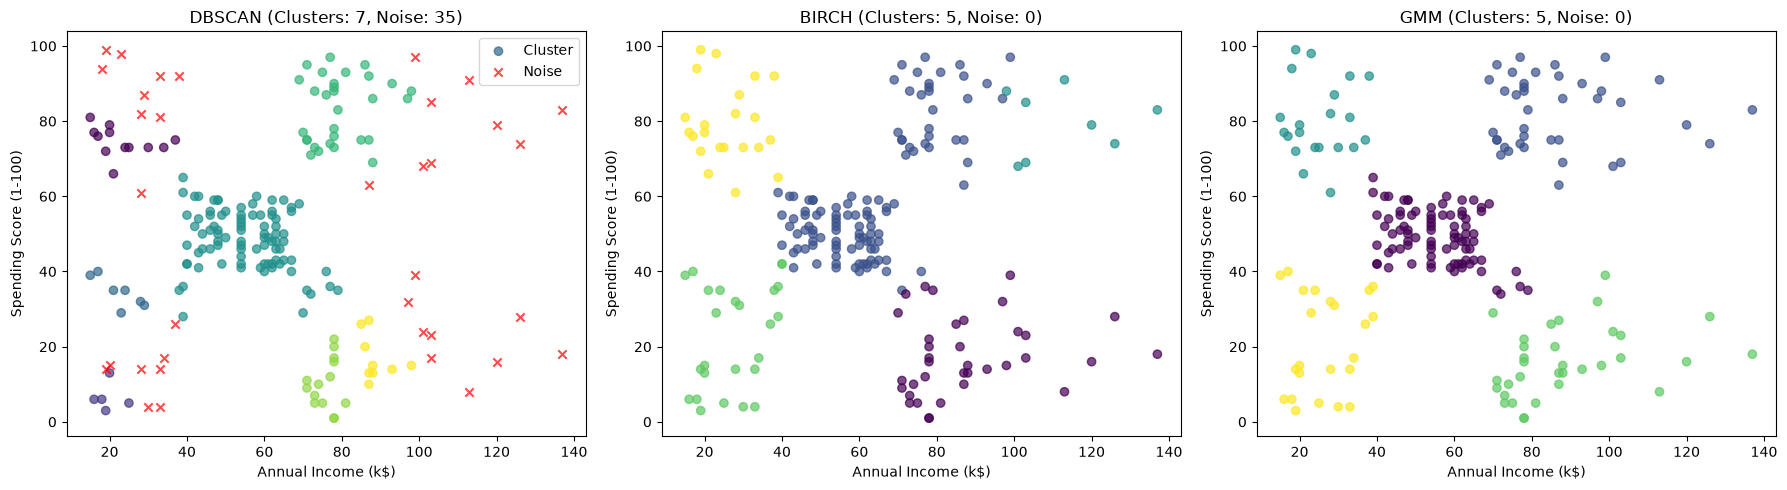

In [24]:
# Buat tiga scatter plot dalam satu baris subplot:
# DBSCAN, BIRCH, dan GMM.
# Gunakan koordinat dari fitur asli X dan warna berdasarkan label cluster.
# Beri judul yang menunjukkan algoritma dan jumlah cluster/noise.

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# DBSCAN
noise_mask = labels_dbscan == -1
axes[0].scatter(
    X["Annual Income (k$)"].to_numpy()[~noise_mask],
    X["Spending Score (1-100)"].to_numpy()[~noise_mask],
    c=labels_dbscan[~noise_mask],
    cmap="viridis",
    alpha=0.7,
    label="Cluster"
)
axes[0].scatter(
    X["Annual Income (k$)"].to_numpy()[noise_mask],
    X["Spending Score (1-100)"].to_numpy()[noise_mask],
    color="red",
    marker="x",
    alpha=0.7,
    label="Noise"
)
axes[0].set_title(f"DBSCAN (Clusters: {ev_dbscan['n_clusters']}, Noise: {ev_dbscan['n_noise']})")
axes[0].set_xlabel("Annual Income (k$)")
axes[0].set_ylabel("Spending Score (1-100)")
axes[0].legend()

# BIRCH
axes[1].scatter(
    X["Annual Income (k$)"].to_numpy(),
    X["Spending Score (1-100)"].to_numpy(),
    c=labels_birch,
    cmap="viridis",
    alpha=0.7
)
axes[1].set_title(f"BIRCH (Clusters: {ev_birch['n_clusters']}, Noise: 0)")
axes[1].set_xlabel("Annual Income (k$)")
axes[1].set_ylabel("Spending Score (1-100)")

# GMM
axes[2].scatter(
    X["Annual Income (k$)"].to_numpy(),
    X["Spending Score (1-100)"].to_numpy(),
    c=labels_gmm,
    cmap="viridis",
    alpha=0.7
)
axes[2].set_title(f"GMM (Clusters: {ev_gmm['n_clusters']}, Noise: 0)")
axes[2].set_xlabel("Annual Income (k$)")
axes[2].set_ylabel("Spending Score (1-100)")

plt.tight_layout()
plt.show()


In [25]:
# Buat profil cluster pada fitur asli.
# Untuk setiap algoritma, tampilkan jumlah anggota serta median dan rata-rata
# Annual Income (k$) dan Spending Score (1-100) untuk setiap cluster.
# Untuk DBSCAN, analisis label -1 (noise) secara terpisah.

def display_cluster_profile(X_df, labels, model_name):
    temp_df = X_df.with_columns(pl.Series("cluster", labels))
    summary = (
        temp_df.group_by("cluster")
        .agg([
            pl.len().alias("count"),
            pl.col("Annual Income (k$)").mean().round(2).alias("income_mean"),
            pl.col("Annual Income (k$)").median().round(2).alias("income_median"),
            pl.col("Spending Score (1-100)").mean().round(2).alias("spending_mean"),
            pl.col("Spending Score (1-100)").median().round(2).alias("spending_median"),
        ])
        .sort("cluster")
    )
    print(f"=== Profil Cluster: {model_name} ===")
    print(summary)
    return summary

profile_dbscan = display_cluster_profile(X, labels_dbscan, "DBSCAN")
profile_birch = display_cluster_profile(X, labels_birch, "BIRCH")
profile_gmm = display_cluster_profile(X, labels_gmm, "GMM")


=== Profil Cluster: DBSCAN ===
shape: (8, 6)
┌─────────┬───────┬─────────────┬───────────────┬───────────────┬─────────────────┐
│ cluster ┆ count ┆ income_mean ┆ income_median ┆ spending_mean ┆ spending_median │
│ ---     ┆ ---   ┆ ---         ┆ ---           ┆ ---           ┆ ---             │
│ i64     ┆ u32   ┆ f64         ┆ f64           ┆ f64           ┆ f64             │
╞═════════╪═══════╪═════════════╪═══════════════╪═══════════════╪═════════════════╡
│ -1      ┆ 35    ┆ 70.6        ┆ 87.0          ┆ 51.66         ┆ 61.0            │
│ 0       ┆ 12    ┆ 23.17       ┆ 20.5          ┆ 74.58         ┆ 74.0            │
│ 1       ┆ 5     ┆ 19.6        ┆ 19.0          ┆ 6.6           ┆ 6.0             │
│ 2       ┆ 7     ┆ 22.43       ┆ 23.0          ┆ 34.43         ┆ 35.0            │
│ 3       ┆ 88    ┆ 55.23       ┆ 54.0          ┆ 48.58         ┆ 49.0            │
│ 4       ┆ 30    ┆ 79.53       ┆ 78.0          ┆ 83.13         ┆ 86.0            │
│ 5       ┆ 14    ┆ 75.93      

### Ringkasan Perbandingan

Lengkapi tabel atau tuliskan rangkuman berdasarkan hasil eksperimen:

| Aspek | DBSCAN | BIRCH | EM/GMM |
|---|---|---|---|
| Perlu menentukan jumlah cluster di awal? | Tidak | Opsional (`None` atau `n_clusters`) | Ya (`n_components`) |
| Dapat memberi label noise secara eksplisit? | Ya (label `-1`) | Tidak | Tidak |
| Parameter yang paling memengaruhi hasil | `eps`, `min_samples` | `threshold`, `n_clusters` | `n_components`, `covariance_type` |
| Bentuk cluster yang dapat dimodelkan | Bentuk bebas / arbitrary berbasis kepadatan | Cenderung bulat / sferis | Elips / multivariat Gaussian |
| Kelebihan | Mampu menyaring noise dan outlier, bentuk cluster tidak dibatasi asumsi geometri | Efisien secara memori dan waktu komputasi untuk data besar via CF-Tree | Memberikan ukuran probabilitas keanggotaan (soft clustering), fleksibel dalam orientasi kovarians |
| Kekurangan | Sensitif terhadap penentuan nilai `eps` dan data dengan variasi kepadatan | Sensitif terhadap batas `threshold`, tidak memfilter titik outlier | Rentan terjebak di local optima, mengasumsikan data mengikuti distribusi normal campuran |


# 7. Analisis

Jelaskan hasil eksperimen dengan merujuk pada output notebook kalian sendiri. Bahas poin-poin berikut:

1. **Mengapa fitur perlu di-scaling sebelum clustering?**
   Algoritma clustering berbasis jarak (seperti jarak Euclidean pada DBSCAN dan perhitungan matriks kovarians pada GMM) sensitif terhadap perbedaan rentang antar-fitur. Pada dataset ini, `Annual Income (k$)` memiliki rentang 15–137 sedangkan `Spending Score (1-100)` memiliki rentang 1–99. Standardisasi memastikan kedua fitur memiliki rata-rata 0 dan varians 1 sehingga berkontribusi secara proporsional dalam perhitungan jarak tanpa dominasi salah satu fitur.

2. **Bagaimana perubahan parameter DBSCAN memengaruhi jumlah cluster dan noise?**
   Berdasarkan ringkasan eksperimen DBSCAN:
   - Menaikkan `eps` (misalnya pada `min_samples=5`, dari 0.2 ke 0.4) memperluas jangkauan pencarian titik inti, sehingga menurunkan titik noise dari 77 menjadi 15 dan mengurangi jumlah cluster dari 7 menjadi 4 karena cluster yang bertetangga melebur.
   - Menaikkan `min_samples` (misalnya pada `eps=0.3`, dari 3 ke 7) memperketat ambang kepadatan untuk membentuk titik inti, sehingga titik noise meningkat dari 14 menjadi 72 dan jumlah cluster berkurang dari 9 menjadi 4.

3. **Bagaimana parameter `threshold` dan `n_clusters` memengaruhi BIRCH?**
   - Parameter `threshold` membatasi radius sub-cluster pada simpul daun CF-Tree. Nilai threshold yang semakin besar menggabungkan lebih banyak titik ke dalam satu sub-cluster (misal tanpa batas `n_clusters`, threshold 0.3 membentuk 23 cluster sedangkan threshold 1.0 membentuk 4 cluster).
   - Parameter `n_clusters` mengontrol tahap akhir global clustering. Ketika `n_clusters=5` ditentukan, BIRCH membagi sub-cluster menjadi 5 cluster; namun pada threshold 1.0, sub-cluster awal pada CF-Tree hanya berjumlah 4, sehingga model tidak dapat membentuk 5 cluster dan menghasilkan 4 cluster.

4. **Apa makna probabilitas keanggotaan GMM dan bagaimana EM menggunakannya?**
   Probabilitas keanggotaan adalah bobot tanggung jawab (*responsibilities*) suatu komponen Gaussian terhadap tiap titik data. Pada tahap Expectation (E-step), algoritma EM menghitung nilai posterior probability tiap titik data terhadap setiap komponen. Pada tahap Maximization (M-step), probabilitas ini dijadikan bobot untuk mengestimasi ulang mean, kovarians, dan proporsi pencampuran masing-masing distribusi.

5. **Model mana yang paling mudah diinterpretasikan pada dataset ini? Jelaskan alasannya.**
   GMM dengan `n_components=5`. Model ini membagi data ke dalam 5 kelompok yang terpisah secara konsisten dengan sebaran 2D fitur pendapatan dan pengeluaran tanpa memecah cluster menjadi bagian-bagian kecil (seperti DBSCAN dengan 7 cluster dan 35 noise) dan tanpa menggabungkan kelompok tengah secara tidak seimbang (seperti BIRCH dengan 109 anggota di satu cluster).

6. **Apakah metrik evaluasi menunjukkan algoritma terbaik yang sama? Jika berbeda, apa kemungkinan penyebabnya?**
   Ketiga metrik internal secara konsisten menempatkan GMM (`n_components=5`) sebagai model terbaik dengan Silhouette Score tertinggi (0.5537), Davies-Bouldin terendah (0.5760), dan Calinski-Harabasz tertinggi (244.94). Sebagai catatan, skor DBSCAN (Silhouette 0.5243) dihitung murni pada 165 titik non-noise; apabila 35 titik noise diikutsertakan dalam kalkulasi, skor Silhouette DBSCAN turun menjadi 0.3161 karena jarak titik noise yang jauh dari pusat cluster.

7. **Jelaskan karakteristik cluster berdasarkan median pendapatan dan spending score. Berikan nama deskriptif pada cluster jika memungkinkan.**
   Berdasarkan profil GMM (5 cluster):
   - **Cluster 0** (84 data): Median Income 55.5 k$, Median Spending 49.5 $\rightarrow$ *Pendapatan Menengah, Pengeluaran Menengah*.
   - **Cluster 1** (39 data): Median Income 79.0 k$, Median Spending 83.0 $\rightarrow$ *Pendapatan Tinggi, Pengeluaran Tinggi*.
   - **Cluster 2** (21 data): Median Income 24.0 k$, Median Spending 77.0 $\rightarrow$ *Pendapatan Rendah, Pengeluaran Tinggi*.
   - **Cluster 3** (33 data): Median Income 86.0 k$, Median Spending 15.0 $\rightarrow$ *Pendapatan Tinggi, Pengeluaran Rendah*.
   - **Cluster 4** (23 data): Median Income 25.0 k$, Median Spending 17.0 $\rightarrow$ *Pendapatan Rendah, Pengeluaran Rendah*.

8. **Apa keterbatasan penggunaan hanya dua fitur dan dataset pelanggan yang berukuran kecil?**
   Penggunaan hanya dua fitur numerik mengesampingkan variabel demografis dan perilaku lainnya (seperti usia dan jenis kelamin) yang dapat mempengaruhi segmentasi. Ukuran dataset yang kecil (200 data) menyebabkan estimasi parameter distribusi pada GMM dan estimasi kepadatan pada DBSCAN sensitif terhadap keberadaan beberapa titik ekstrem, serta membatasi generalisasi hasil segmentasi ke populasi yang lebih luas.


# 8. Kesimpulan dan Saran

Tuliskan kesimpulan berdasarkan eksperimen:

- **Algoritma mana yang memberikan hasil paling berguna untuk dataset ini?**
  GMM (Gaussian Mixture Model) dengan `n_components=5`. Model ini menghasilkan pemisahan 5 segmen yang konsisten dengan struktur data, didukung oleh nilai Silhouette Score tertinggi (0.5537), Davies-Bouldin terendah (0.5760), dan Calinski-Harabasz tertinggi (244.94).

- **Parameter apa yang dipilih dan mengapa?**
  - GMM: `n_components=5`, `covariance_type='full'`, `random_state=42`, karena menghasilkan nilai BIC terendah (1058.65) dan Silhouette Score optimal.
  - DBSCAN: `eps=0.3, min_samples=5` sebagai baseline kepadatan lokal (7 cluster, 35 noise).
  - BIRCH: `threshold=0.5, n_clusters=5` untuk membentuk ringkasan 5 cluster dari struktur CF-Tree.

- **Apa perbedaan utama DBSCAN, BIRCH, dan EM/GMM yang kalian pelajari?**
  - DBSCAN berbasis kepadatan lokal dan mampu mendeteksi titik noise secara eksplisit tanpa asumsi bentuk cluster.
  - BIRCH berbasis pohon hierarki (CF-Tree) yang mengelompokkan data secara inkremental dan efisien untuk data besar, tetapi mengasumsikan cluster sferis dan tidak mendeteksi noise.
  - GMM/EM berbasis model probabilistik campuran Gaussian yang menghasilkan probabilitas keanggotaan (soft clustering) dan fleksibel terhadap varians elips.

- **Eksperimen lanjutan apa yang dapat dilakukan?**
  - Memasukkan fitur demografis seperti `Age` atau menguji segmentasi berdasarkan `Gender`.
  - Menguji teknik reduksi dimensi jika fitur bertambah banyak (misal PCA atau t-SNE/UMAP).
  - Menguji variasi struktur kovarians pada GMM (`tied`, `diag`, `spherical`) untuk melihat kecocokan bentuk sebaran data.


## Referensi

- Dataset: [Mall Customer Segmentation Data, Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data)
- Dokumentasi DBSCAN: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- Dokumentasi BIRCH: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html)
- Dokumentasi Gaussian Mixture: [scikit-learn](https://scikit-learn.org/stable/modules/mixture.html#gaussian-mixture)